# 06b · Second prediction: how many minutes late will this flight leave?

**Why this question** (notebook 02): cancellation is too rare in the test months (224 flights) to score honestly. The number of minutes of delay is a different question that the business can use: *tell clients to expect a long delay, and check their connections*.

**For whom and when.** For every flight that leaves, **2 hours before its scheduled departure**, we predict its departure delay in minutes (a negative number means it leaves early). Cancelled flights have no delay, so they are not part of this question; the first prediction covers them.

**How we test honestly**: the same time split as notebook 06a (fit = Jan-Jun, valid = Jul-Sep, final test = Oct-Dec opened once at the end, enforced by an automatic check).

**Which score?** The **average error in minutes** (MAE): on average, how many minutes is the prediction away from the real delay. The dumb answer is *"every flight leaves at the usual delay"* (the median of the training months, which is a couple of minutes early). A model that does not beat it is reported as such and is not used.

**A trap with delays.** A few flights are delayed by 10 to 30 hours. A model that minimises *squared* errors tries to predict the **average**, which those few flights pull far above what a normal flight sees, so its predictions are often too high. We therefore (1) train the simple model on a **signed-log** version of the delay (a 30-hour delay counts as a bit more than a 3-hour delay, not ten times more), and (2) train the boosting model to minimise the **absolute** error. Both then aim at the *typical* delay, which is what the MAE rewards.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from src import common, viz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

common.require_processed("features.parquet", "destination_groups.parquet")
viz.apply_style()
pd.set_option("display.width", 170)
choice = pd.read_csv(common.REPORTS / "02_second_prediction.csv").loc[0, "choice"]
assert choice == "minutes_late", "notebook 02 chose the fallback prediction; this notebook is written for 'minutes_late'"

In [2]:
features = pd.read_parquet(common.PROC / "features.parquet")
dev = features[features["part"].isin(["fit", "valid"]) & features["dep_delay"].notna()].reset_index(drop=True)
del features   # from here until the final section, only the training months are in memory
dev_tune = dev.assign(dest_group=dev["dest_group_fit"])      # tuning stage: destination groups built from January-June only, so no valid-month outcome leaks into the comparison
fit, valid = dev_tune[dev_tune["part"] == "fit"], dev_tune[dev_tune["part"] == "valid"]
y_fit, y_valid, y_dev = fit["dep_delay"].to_numpy(), valid["dep_delay"].to_numpy(), dev["dep_delay"].to_numpy()
print(f"flights that left: fit {len(fit):,} | valid {len(valid):,}")
print(f"delay in minutes: median {np.median(y_dev):.0f}, mean {y_dev.mean():.1f}, 99th percentile {np.quantile(y_dev, 0.99):.0f}, largest {y_dev.max():.0f}")

flights that left: fit 217,441 | valid 102,928
delay in minutes: median -2, mean 16.4, 99th percentile 250, largest 1742


## 1. Columns used, and columns removed
The same 18 input columns as notebook 06a, all known 2 hours before departure. The columns removed as leakage are the same ones listed in `reports/06_leakage_removed.csv` (written by notebook 06a): the actual departure and arrival times and delays, the air time, and anything built from them.

In [3]:
NUM = ["hour", "distance", "origin_hour_flights", "plane_age", "seats", "temp", "wind_speed", "wind_gust", "visib", "precip", "pressure",
       "prev_dep_delay", "weather_filled", "prev_known"]
CAT = ["carrier", "origin", "dest_group", "weekday"]
leakage = pd.read_csv(common.REPORTS / "06_leakage_removed.csv")
assert not (set(leakage["column"]) & set(NUM + CAT))
print(f"{len(NUM) + len(CAT)} input columns | leakage list ({len(leakage)} entries) read from notebook 06a")

18 input columns | leakage list (11 entries) read from notebook 06a


## 2. The scores
**MAE** is the headline. We also show the **median error** (what a usual flight sees) and the MAE **without the 1% most delayed flights** (to show how much a handful of extreme delays weigh).

In [4]:
def mae_scores(y, pred):
    err = np.abs(y - pred)
    return {"mae_minutes": err.mean(), "median_error_minutes": np.median(err),
            "mae_minutes_without_top1pct": err[y < np.quantile(y, 0.99)].mean()}

def signed_log(y):
    return np.sign(y) * np.log1p(np.abs(y))

def signed_exp(z):
    return np.sign(z) * np.expm1(np.abs(z))

## 3. The dumb answer
Every flight gets the usual delay of the training months (their median).

In [5]:
usual_fit = np.median(y_fit)
valid_scores = {"dumb_median": mae_scores(y_valid, np.full(len(y_valid), usual_fit))}
print(f"usual delay in the fit months: {usual_fit:.0f} minutes")
print(pd.DataFrame(valid_scores).T.round(2).to_string())

usual delay in the fit months: -2 minutes
             mae_minutes  median_error_minutes  mae_minutes_without_top1pct
dumb_median        26.12                   5.0                        21.69


## 4. Two models
1. **Ridge regression** (a linear model with a safety brake against over-fitting, strength `alpha`), on the signed-log delay.
2. **Gradient boosting** (`HistGradientBoostingRegressor`, absolute-error loss): many small decision trees correcting each other. Tuned: learning rate and tree size.

The input columns are prepared as in notebook 06a (median fill plus a "was missing" flag, scaling, one-hot categories; boosting reads missing values and categories natively), with **one addition: every scaled number is capped at 5 standard deviations**. Without it, a straight-line model reading an earlier delay of 1,700 minutes extrapolates absurdly: our first attempt predicted delays of up to **4 million minutes** and scored 70 minutes of average error against 26 for the dumb answer. Capping the inputs keeps predictions in a sane range (found by looking at the valid months only). **Tuning uses the valid months only**, with the January-to-June version of the destination-type column (see notebook 05).

In [6]:
def cap_at_5(a):
    return np.clip(a, -5, 5)

def make_prep():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler()),
                          ("cap", FunctionTransformer(cap_at_5))]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

CATEGORIES = {c: sorted(dev[c].unique()) for c in CAT}
def as_categorical(d):
    out = d[NUM + CAT].copy()
    for c in CAT:
        out[c] = pd.Categorical(out[c], categories=CATEGORIES[c])
    return out

def ridge_model(alpha):
    return Pipeline([("prep", make_prep()), ("ridge", Ridge(alpha=alpha, random_state=common.SEED))])

def gb_model(lr, leaves):
    return HistGradientBoostingRegressor(loss="absolute_error", learning_rate=lr, max_leaf_nodes=leaves, max_iter=200, l2_regularization=1.0,
                                         categorical_features="from_dtype", early_stopping=False, random_state=common.SEED)

**Ridge: which `alpha`?**

In [7]:
ridge_tuning = {}
for alpha in [0.1, 1, 10]:
    pipe = ridge_model(alpha).fit(fit[NUM + CAT], signed_log(y_fit))
    pred = signed_exp(pipe.predict(valid[NUM + CAT]))
    ridge_tuning[alpha] = (mae_scores(y_valid, pred)["mae_minutes"], pipe)
best_alpha = min(ridge_tuning, key=lambda a: ridge_tuning[a][0])
print({a: round(v[0], 3) for a, v in ridge_tuning.items()}, "-> best alpha =", best_alpha)
ridge_fit = ridge_tuning[best_alpha][1]
predict_fit = {"ridge": lambda d: signed_exp(ridge_fit.predict(d[NUM + CAT]))}

{0.1: np.float64(25.36), 1: np.float64(25.36), 10: np.float64(25.36)} -> best alpha = 0.1


**Gradient boosting: which learning rate and tree size?**

In [8]:
gb_tuning = {}
X_fit_cat, X_valid_cat = as_categorical(fit), as_categorical(valid)
for lr in [0.05, 0.1]:
    for leaves in [15, 31, 63]:
        m = gb_model(lr, leaves).fit(X_fit_cat, y_fit)
        gb_tuning[(lr, leaves)] = (mae_scores(y_valid, m.predict(X_valid_cat))["mae_minutes"], m)
best_gb = min(gb_tuning, key=lambda k: gb_tuning[k][0])
print({k: round(v[0], 3) for k, v in gb_tuning.items()}, "\n-> best (learning rate, leaves) =", best_gb)
gb_fit = gb_tuning[best_gb][1]
predict_fit["gradient_boosting"] = lambda d: gb_fit.predict(as_categorical(d))

{(0.05, 15): np.float64(24.715), (0.05, 31): np.float64(25.048), (0.05, 63): np.float64(25.217), (0.1, 15): np.float64(25.253), (0.1, 31): np.float64(25.725), (0.1, 63): np.float64(25.668)} 
-> best (learning rate, leaves) = (0.05, 15)


## 5. Compare on the valid months (for choosing only)

In [9]:
for name, fn in predict_fit.items():
    valid_scores[name] = mae_scores(y_valid, fn(valid))
valid_table = pd.DataFrame(valid_scores).T
common.REPORTS.mkdir(parents=True, exist_ok=True)
valid_table.round(4).rename_axis("model").reset_index().melt(id_vars="model", var_name="metric", value_name="value").to_csv(common.REPORTS / "06b_valid_results.csv", index=False)
print(valid_table.round(2).to_string())
best_model = min(["ridge", "gradient_boosting"], key=lambda m: valid_scores[m]["mae_minutes"])
print("\nbest model on valid:", best_model)

                   mae_minutes  median_error_minutes  mae_minutes_without_top1pct
dumb_median              26.12                  5.00                        21.69
ridge                    25.36                  6.44                        20.98
gradient_boosting        24.71                  6.41                        20.38

best model on valid: gradient_boosting


## 6. What does the best model rely on? (permutation importance)
We shuffle one column at a time on the valid months and see how much the average error grows. A big increase means the model relies on that column.

In [10]:
def permutation_importance(predict_fn, frame, y, repeats=3):
    rng = np.random.default_rng(common.SEED)
    base = np.abs(y - predict_fn(frame)).mean()
    rows = []
    for col in NUM + CAT:
        growth = []
        for _ in range(repeats):
            shuffled = frame.copy()
            shuffled[col] = rng.permutation(shuffled[col].to_numpy())
            growth.append(np.abs(y - predict_fn(shuffled)).mean() - base)
        rows.append({"feature": col, "importance_mean": float(np.mean(growth)), "importance_std": float(np.std(growth))})
    return pd.DataFrame(rows).sort_values("importance_mean", ascending=False).reset_index(drop=True)

importance = permutation_importance(predict_fit[best_model], valid[NUM + CAT], y_valid)
importance.round(4).to_csv(common.REPORTS / "06b_importance.csv", index=False)
print(importance.head(8).round(3).to_string(index=False))

       feature  importance_mean  importance_std
          hour            1.034           0.026
prev_dep_delay            0.966           0.011
       carrier            0.523           0.001
        precip            0.385           0.004
          temp            0.344           0.005
         seats            0.077           0.006
        origin            0.077           0.004
         visib            0.072           0.006


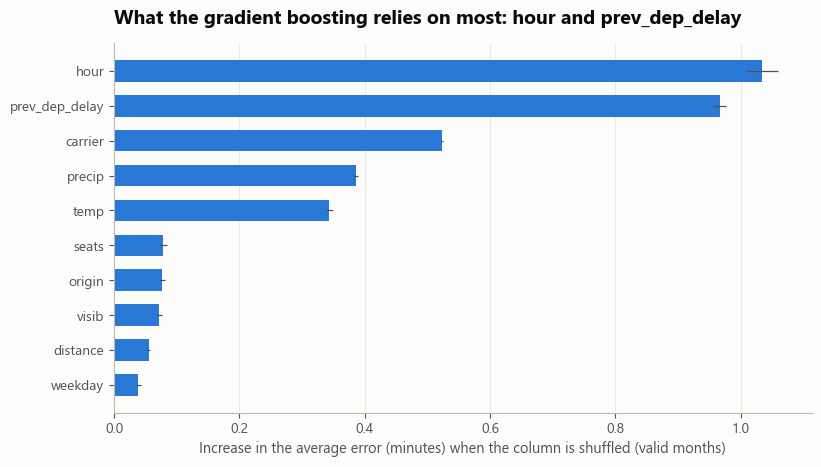

In [11]:
top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color=viz.BLUE, height=0.62, error_kw={"ecolor": viz.INK_2, "elinewidth": 0.9})
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_title(f"What the {best_model.replace('_', ' ')} relies on most: {importance.loc[0, 'feature']} and {importance.loc[1, 'feature']}")
ax.set_xlabel("Increase in the average error (minutes) when the column is shuffled (valid months)")
chart_importance = viz.save_figure(fig, "06b_importance.png")
plt.show()

## 7. Train again on January to September with the chosen settings
As in 06a, the final models use fit and valid together. Nothing about the test months has been used so far.

In [12]:
usual_dev = np.median(y_dev)
ridge_final = ridge_model(best_alpha).fit(dev[NUM + CAT], signed_log(y_dev))
gb_final = gb_model(*best_gb).fit(as_categorical(dev), y_dev)
final_fns = {"ridge": lambda d: signed_exp(ridge_final.predict(d[NUM + CAT])), "gradient_boosting": lambda d: gb_final.predict(as_categorical(d))}
print(f"final models trained on {len(dev):,} flights from January to September | usual delay: {usual_dev:.0f} minutes")

final models trained on 320,369 flights from January to September | usual delay: -2 minutes


## 8. FINAL TEST: October to December, opened once
From here on we look at the held-out months. No model is changed after seeing these numbers.

In [13]:
# ---- FINAL TEST (run once) ----
features = pd.read_parquet(common.PROC / "features.parquet")
held = features[~features["part"].isin(["fit", "valid"]) & features["dep_delay"].notna()].reset_index(drop=True)
y_held = held["dep_delay"].to_numpy()
print(f"{len(held):,} held-out flights that left | usual delay in these months: median {np.median(y_held):.0f}, mean {y_held.mean():.1f}")
pred_held = {name: fn(held) for name, fn in final_fns.items()}
test_scores = {"dumb_median": mae_scores(y_held, np.full(len(y_held), usual_dev))}
test_scores.update({name: mae_scores(y_held, pred) for name, pred in pred_held.items()})
test_table = pd.DataFrame(test_scores).T
test_table.round(4).rename_axis("model").reset_index().melt(id_vars="model", var_name="metric", value_name="value").to_csv(common.REPORTS / "06b_results.csv", index=False)
print(test_table.round(2).to_string())

104,245 held-out flights that left | usual delay in these months: median -4, mean 6.0


                   mae_minutes  median_error_minutes  mae_minutes_without_top1pct
dumb_median              13.27                  5.00                        10.64
ridge                    13.46                  5.84                        10.91
gradient_boosting        13.12                  4.48                        10.60


**Reading the test results (a modest, honest gain)**
- **Gradient boosting is the only model that beats the dumb answer on the held-out months**, and only slightly: an average error of about 13.1 minutes against 13.3 (1% less), and a median error of 4.5 minutes against 5.0 (10% less).
- **Ridge regression does not beat the dumb answer on October-December** (13.5 minutes against 13.3), although it did on the valid months (25.4 against 26.1). The valid months were stormy, with many long delays where a trend helps; the held-out months are calm, and a flight is usually within a few minutes of the schedule, which the dumb answer already guesses well. We report it as it is and **do not use it**. We do not tune it on these numbers.
- **Why the gain is small.** Delays have a heavy tail: a handful of flights are 5 to 30 hours late and nothing in the data can foresee them, yet they weigh heavily in the average. Even without the 1% most delayed flights the model gains almost nothing in average error (10.6 against 10.6). The model is **not** more accurate for the usual flight: it is within 15 minutes of the real delay a little *less* often than the dumb answer (82% against 85%) because it predicts longer delays for risky flights, and those flights often leave on time anyway. Its value is in **ranking**: the flights with the highest predicted delay are the ones with the long tail (see the last chart), which is how decision card 2 uses it.

In [14]:
best_pred = pred_held[best_model]
pd.DataFrame({"row_id": held["row_id"], "pred": best_pred, "y_true": y_held}).to_parquet(common.PROC / "predictions_test_second.parquet", index=False)
err = np.abs(y_held - best_pred)
dumb_err = np.abs(y_held - usual_dev)
print(f"best model ({best_model}): typical error {np.median(err):.1f} min, average error {err.mean():.1f} min; dumb answer: typical {np.median(dumb_err):.1f}, average {dumb_err.mean():.1f}")
print(f"share of flights within 15 minutes of the prediction: model {(err <= 15).mean():.0%} | dumb answer {(dumb_err <= 15).mean():.0%}")
print(f"saved predictions: {len(held):,} rows")

best model (gradient_boosting): typical error 4.5 min, average error 13.1 min; dumb answer: typical 5.0, average 13.3
share of flights within 15 minutes of the prediction: model 82% | dumb answer 85%
saved predictions: 104,245 rows


## 9. Where is the model wrong, and does it treat groups differently?
For each group: how many flights, the average error of the dumb answer and of the model, and how much closer the model gets (in minutes). We flag groups where the model's error is more than 10 minutes above the group's best, among groups with at least 2,000 flights.

In [15]:
groups = pd.read_parquet(common.PROC / "destination_groups.parquet").drop_duplicates("group_id").set_index("group_id")["group_name"]
held = held.assign(model_err=err, dumb_err=dumb_err)
held["hour_band"] = pd.cut(held["hour"], [-1, 11, 17, 24], labels=["Morning (before noon)", "Afternoon (noon to 6 pm)", "Evening (6 pm on)"]).astype(str)
held["dest_group_name"] = held["dest_group"].map(groups)
rows = []
for dimension, col in [("carrier", "carrier"), ("origin", "origin"), ("dest_group", "dest_group_name"), ("hour_band", "hour_band")]:
    for level, g in held.groupby(col):
        values = {"mae_model": g["model_err"].mean(), "mae_dumb": g["dumb_err"].mean(), "minutes_gained": g["dumb_err"].mean() - g["model_err"].mean()}
        rows += [dict(dimension=dimension, level=level, n=len(g), metric=m, value=v) for m, v in values.items()]
group_errors = pd.DataFrame(rows)
group_errors.round(4).to_csv(common.REPORTS / "06b_group_errors.csv", index=False)
mae = group_errors[(group_errors["metric"] == "mae_model") & (group_errors["n"] >= 2000)]
for dimension, g in mae.groupby("dimension"):
    gap = g["value"].max() - g["value"].min()
    print(f"{dimension:11s} average error from {g['value'].min():.1f} min ({g.loc[g['value'].idxmin(), 'level']}) to {g['value'].max():.1f} min ({g.loc[g['value'].idxmax(), 'level']}) | gap {gap:.1f} min{'  <- above 10 minutes' if gap > 10 else ''}")

carrier     average error from 7.3 min (YX) to 21.4 min (B6) | gap 14.1 min  <- above 10 minutes
dest_group  average error from 10.7 min (Steady regional routes) to 14.9 min (Afternoon build-up routes) | gap 4.2 min
hour_band   average error from 9.7 min (Morning (before noon)) to 17.7 min (Evening (6 pm on)) | gap 8.1 min
origin      average error from 12.0 min (LGA) to 14.4 min (JFK) | gap 2.4 min


**Reading the group results.** The errors are larger where delays are larger: by airline from about 7 minutes (Republic Airline) to about 21 minutes (JetBlue Airways), by time of day from about 10 minutes in the morning to about 18 in the evening. The gaps between destination types (4 minutes) and origin airports (2 minutes) are small. As in 06a these are airlines, airports and hours, not people; the gaps follow how late each group usually is, and the card for this prediction lists them as a weak spot.

## 10. Charts for the business

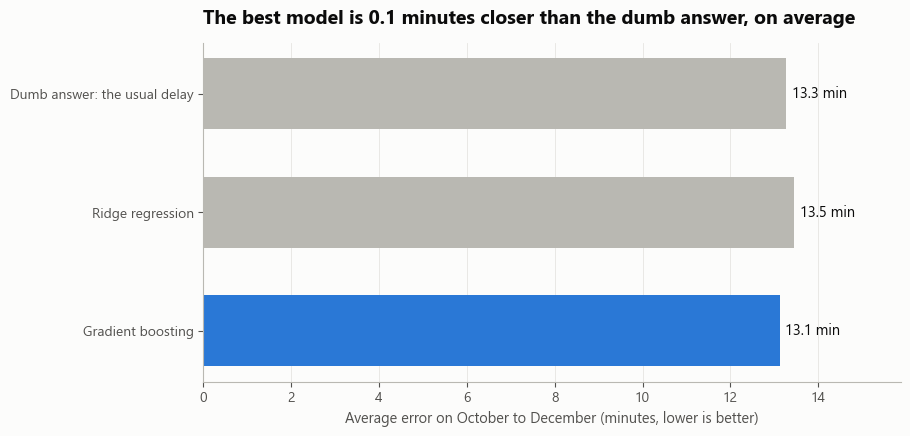

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.4))
names = {"dumb_median": "Dumb answer: the usual delay", "ridge": "Ridge regression", "gradient_boosting": "Gradient boosting"}
mae_t = test_table["mae_minutes"].reindex(list(names))
ax.barh([names[m] for m in mae_t.index][::-1], mae_t.values[::-1], color=[viz.BLUE if m == best_model else viz.GREY for m in mae_t.index][::-1], height=0.6)
for i, v in enumerate(mae_t.values[::-1]):
    ax.annotate(f"{v:.1f} min", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=10.5)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlim(0, mae_t.max() * 1.18)
ax.set_title(f"The best model is {mae_t['dumb_median'] - mae_t[best_model]:.1f} minutes closer than the dumb answer, on average")
ax.set_xlabel("Average error on October to December (minutes, lower is better)")
chart_scores = viz.save_figure(fig, "06b_model_scores.png")
plt.show()

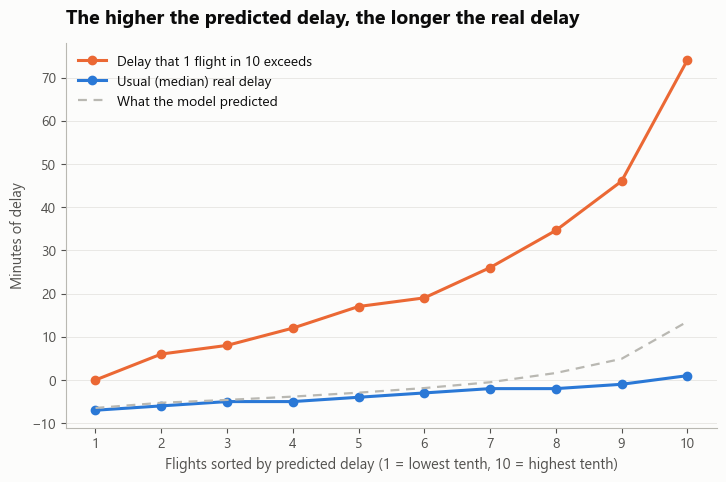

     predicted  actual_median  actual_p90
bin                                      
1         -6.5           -7.0         0.0
2         -5.3           -6.0         6.0
3         -4.6           -5.0         8.0
4         -3.8           -5.0        12.0
5         -2.9           -4.0        17.0
6         -1.9           -3.0        19.0
7         -0.5           -2.0        26.0
8          1.6           -2.0        34.6
9          4.9           -1.0        46.0
10        13.5            1.0        74.0


In [17]:
tab = pd.DataFrame({"pred": best_pred, "actual": y_held})
tab["bin"] = pd.qcut(tab["pred"].rank(method="first"), 10, labels=False) + 1
by_bin = tab.groupby("bin").agg(predicted=("pred", "median"), actual_median=("actual", "median"), actual_p90=("actual", lambda s: s.quantile(0.9)))
fig, ax = plt.subplots(figsize=(8.4, 5))
ax.plot(by_bin.index, by_bin["actual_p90"], color=viz.ORANGE, linewidth=2.2, marker="o", label="Delay that 1 flight in 10 exceeds")
ax.plot(by_bin.index, by_bin["actual_median"], color=viz.BLUE, linewidth=2.2, marker="o", label="Usual (median) real delay")
ax.plot(by_bin.index, by_bin["predicted"], color=viz.GREY, linewidth=1.6, linestyle=(0, (4, 3)), label="What the model predicted")
ax.set_xticks(range(1, 11)); ax.set_xlabel("Flights sorted by predicted delay (1 = lowest tenth, 10 = highest tenth)")
ax.set_ylabel("Minutes of delay")
ax.legend(loc="upper left")
ax.set_title("The higher the predicted delay, the longer the real delay")
chart_bins = viz.save_figure(fig, "06b_by_predicted_tenth.png")
plt.show()
print(by_bin.round(1).to_string())